In [170]:
# import numpy as np

# # 网格步长（米）
# dx, dy, dz = 0.5, 0.5, 0.5

# # 模型尺寸（米）
# Lx, Ly, Lz = 30.0, 120.0, 30.0

# # 计算网格点数（整数）
# nx = int(Lx / dx)
# ny = int(Ly / dy)
# nz = int(Lz / dz)

# # 构造速度模型（单位 km/s）
# vp = np.ones((nx, ny, nz), dtype=np.float32) * 5000.0

# # ========== 圆柱体隧道 ==========
# # 原矩形范围：x 从 10/dx 到 20/dx，z 从 10/dz 到 20/dz，y 从 0 到 20/dy
# # 使用网格索引计算中心
# cx_idx = int((10/dx + 20/dx) / 2)   # 例如 15
# cz_idx = int((10/dz + 20/dz) / 2)   # 例如 15
# radius_idx = min((20-10)/dx, (20-10)/dz) / 2   # 取边长一半，约 5 网格单位

# # Y 方向范围（与原矩形一致）
# y_min_idx = 0
# y_max_idx = int(20/dy)   # 例如 40

# # 生成坐标网格（用于向量化掩码）
# x = np.arange(nx).reshape(-1, 1, 1)   # (nx,1,1)
# y = np.arange(ny).reshape(1, -1, 1)   # (1,ny,1)
# z = np.arange(nz).reshape(1, 1, -1)   # (1,1,nz)

# # 计算到圆柱轴（平行于 Y）的距离平方
# dist2 = (x - cx_idx)**2 + (z - cz_idx)**2

# # 构建掩码：在 Y 范围内且距离 ≤ 半径
# mask = (y >= y_min_idx) & (y < y_max_idx) & (dist2 <= radius_idx**2)

# # 赋值
# vp[mask] = 0.001   # 隧道速度
# vp_0 = vp.copy()
# vp[:,120:160,:] = 3000

In [171]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "1"

import cupy as cp

In [172]:
import numpy as np
data = np.load("/root/my_data/model_build/model/model0.npz")
data.files

['vp', 'geo_info', 'fault_info', 'fracture_info', 'cavity_info']

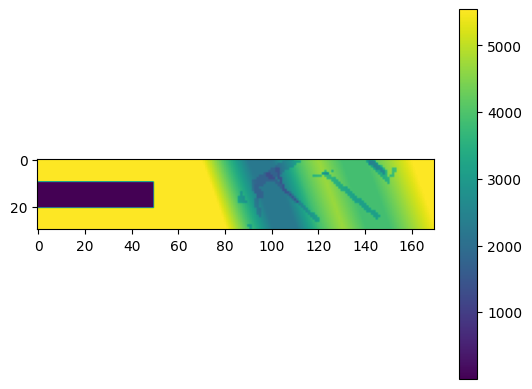

In [173]:
import matplotlib.pyplot as plt
vp = data['vp']
plt.imshow(vp[15,:,:].T)
plt.colorbar()

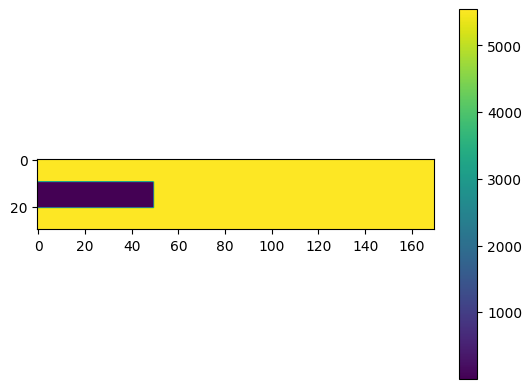

In [174]:
# 网格步长（米）
dx, dy, dz = 1, 1, 1
vp_0 = vp.copy()
vp_0[:,50:,:] = vp.max()
plt.imshow(vp_0[15,:,:].T)
plt.colorbar()

In [175]:
import numpy as np

# -----------------------------
# source
# -----------------------------
source_list = [
    (8.0,45.0,15.0),
    (22.0,45.0,15.0)
]


# -----------------------------
# receivers
# -----------------------------

# 左侧检波器
receiver_left = np.array(
    [
        [8.0, y, 15.0]
        for y in np.linspace(35.0, 25.0, 6)
    ],
    dtype=np.float32,
)

# 右侧检波器
receiver_right = np.array(
    [
        [22.0, y, 15.0]
        for y in np.linspace(35.0, 25.0, 6)
    ],
    dtype=np.float32,
)


# 合并观测系统
receiver_xyz = np.vstack(
    (
        receiver_left,
        receiver_right,
    )
)


# print(source_xyz)

# print(receiver_xyz)

In [176]:
from acoustic3d_cpml_gpu import acoustic3d_cpml_gpu
from __future__ import annotations

from typing import Optional, Sequence, Tuple, Union

import numpy as np
import cupy as cp

import matplotlib.pyplot as plt


dt = 5.0e-5
nt = 1500
f0 = 200.0
n_pml = 40

seismic_records = []
seismic_records_k = [] #空模型的波场，用于去除直达波和隧道干扰

seismic_wavefields = []

seismic_snapshot_steps = []

for src in source_list:

    seismograms_gpu, wavefield_gpu,snapshot_steps = acoustic3d_cpml_gpu(
        vp=vp,
        dx=dx,
        dt=dt,
        nt=nt,
        f0=f0,
        snapshot_stride = 5,
        source_xyz=src,
        receiver_xyz=receiver_xyz,
        n_pml=n_pml,
        save_wavefield=True,  # True stores every padded 3-D pressure field on GPU.
    )

    seismograms_gpu_k, wavefield_gpu_k,snapshot_steps_k = acoustic3d_cpml_gpu(
        vp=vp_0,
        dx=dx,
        dt=dt,
        nt=nt,
        f0=f0,
        snapshot_stride = 5,
        source_xyz=src,
        receiver_xyz=receiver_xyz,
        n_pml=n_pml,
        save_wavefield=True,  # True stores every padded 3-D pressure field on GPU.
    )

    seismograms = cp.asnumpy(seismograms_gpu)
    seismograms_k = cp.asnumpy(seismograms_gpu_k)
    seismic_records.append(seismograms)
    seismic_records_k.append(seismograms_k)

    seismic_wavefields.append(wavefield_gpu)

    seismic_snapshot_steps.append(snapshot_steps)




In [177]:
len(seismic_records)

2

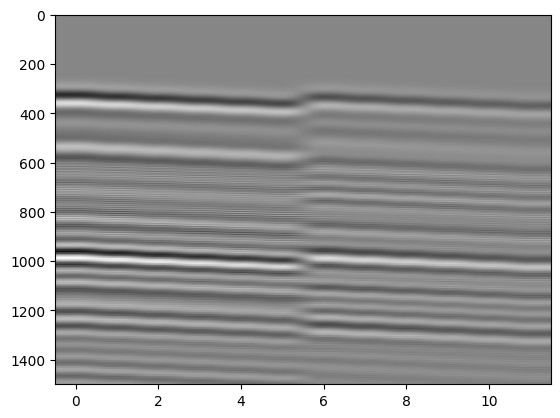

In [178]:
plt.imshow(seismic_records[0]-seismic_records_k[0],aspect="auto",cmap='gray')

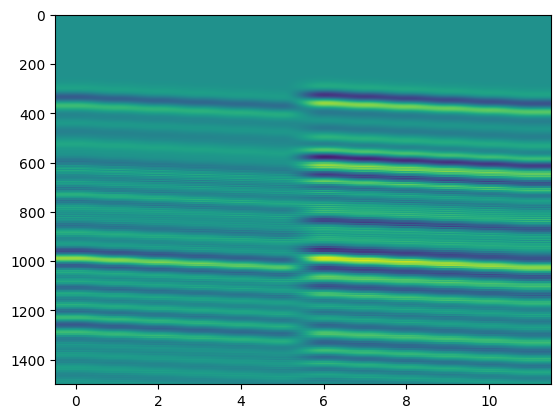

In [179]:
plt.imshow(seismic_records[1]-seismic_records_k[1],aspect="auto")

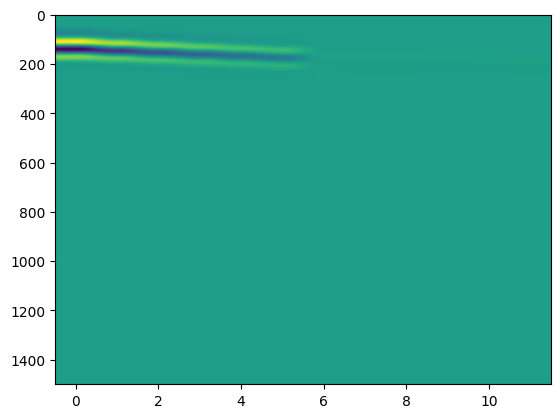

In [180]:
plt.imshow(seismic_records[0],aspect="auto")

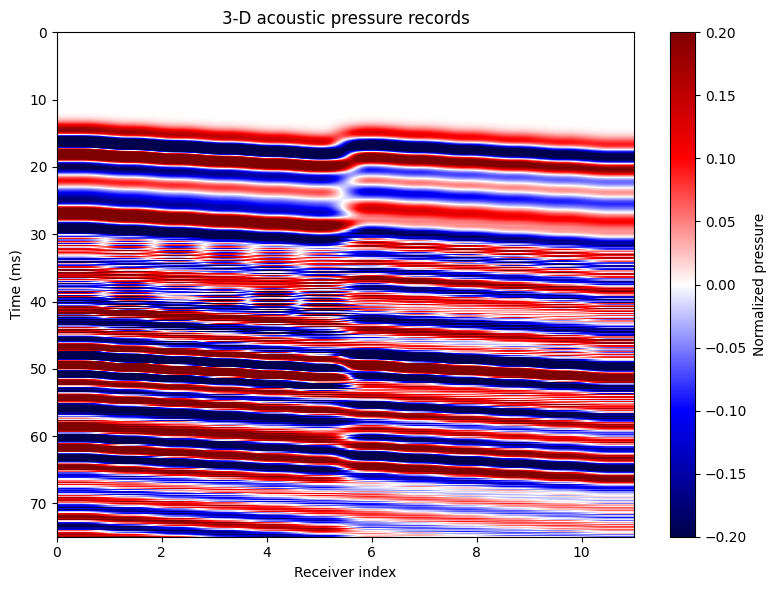

In [181]:
seismograms = cp.asnumpy(seismograms_gpu)
seismograms_k = cp.asnumpy(seismograms_gpu_k)
time_ms = np.arange(nt) * dt * 1.0e3

scale = np.max(np.abs(seismic_records[0]-seismic_records_k[0])) + 1.0e-12
plt.figure(figsize=(8, 6))
plt.imshow(
    (seismic_records[0]-seismic_records_k[0]) / scale,
    aspect="auto",
    cmap="seismic",
    extent=[0, 11, time_ms[-1], time_ms[0]],
    vmin=-0.2,
    vmax=0.2,
)
plt.xlabel("Receiver index")
plt.ylabel("Time (ms)")
plt.title("3-D acoustic pressure records")
plt.colorbar(label="Normalized pressure")
plt.tight_layout()
plt.show()

In [182]:
seismic_wavefields[0].shape

(300, 250, 110)

In [183]:
# from save_wavefield_video_2d import save_wavefield_video
# save_wavefield_video(
#     slice_wavefield_gpu=seismic_wavefields[0],
#     snapshot_steps=seismic_snapshot_steps[0],
#     dx=dx,
#     dt=dt,
#     output_path="/root/my_data/model_build/forward/Tunnel_yz_wavefield_compex.mp4",
#     slice_type="yz",
#     # fps=10,
#     n_pml=n_pml,
#     show_pml=True,
# )

In [184]:
# save_wavefield_video(
#     slice_wavefield_gpu=seismic_wavefields[1],
#     snapshot_steps=seismic_snapshot_steps[1],
#     dx=dx,
#     dt=dt,
#     output_path="/root/my_data/model_build/forward/Tunnel_yz_wavefield_2.mp4",
#     slice_type="yz",
#     # fps=10,
#     n_pml=n_pml,
# )

In [185]:
recv_left = seismic_records[0]-seismic_records_k[0]
recv_right = seismic_records[1]-seismic_records_k[1]
recv= np.stack([recv_left, recv_right], axis=2)
recv.shape

(1500, 12, 2)

In [186]:
import numpy as np
from numba import njit, int32, float64

# -------------------- Numba helpers: array-based min-heap --------------------
@njit
def heap_push(heap_val, hx, hy, hz, heap_size, val, x, y, z):
    """
    push (val, x,y,z) into heap (min-heap)
    heap arrays are preallocated; heap_size is current size
    returns new heap_size
    """
    i = heap_size
    heap_val[i] = val
    hx[i] = x
    hy[i] = y
    hz[i] = z
    heap_size += 1

    # sift-up
    while i > 0:
        parent = (i - 1) // 2
        if heap_val[parent] <= heap_val[i]:
            break
        # swap
        tmp = heap_val[parent]; heap_val[parent] = heap_val[i]; heap_val[i] = tmp
        tx = hx[parent]; hx[parent] = hx[i]; hx[i] = tx
        ty = hy[parent]; hy[parent] = hy[i]; hy[i] = ty
        tz = hz[parent]; hz[parent] = hz[i]; hz[i] = tz
        i = parent
    return heap_size

@njit
def heap_pop(heap_val, hx, hy, hz, heap_size):
    """
    pop min element; returns (val, x,y,z, new_heap_size)
    If heap_size==0, returns large val and zeros (caller should check)
    """
    if heap_size == 0:
        return 1e20, 0, 0, 0, 0
    val = heap_val[0]
    x = hx[0]; y = hy[0]; z = hz[0]
    heap_size -= 1
    if heap_size > 0:
        heap_val[0] = heap_val[heap_size]
        hx[0] = hx[heap_size]; hy[0] = hy[heap_size]; hz[0] = hz[heap_size]
        i = 0
        # sift-down
        while True:
            left = 2 * i + 1
            right = left + 1
            smallest = i
            if left < heap_size and heap_val[left] < heap_val[smallest]:
                smallest = left
            if right < heap_size and heap_val[right] < heap_val[smallest]:
                smallest = right
            if smallest == i:
                break
            # swap i and smallest
            tmp = heap_val[i]; heap_val[i] = heap_val[smallest]; heap_val[smallest] = tmp
            tx = hx[i]; hx[i] = hx[smallest]; hx[smallest] = tx
            ty = hy[i]; hy[i] = hy[smallest]; hy[smallest] = ty
            tz = hz[i]; hz[i] = hz[smallest]; hz[smallest] = tz
            i = smallest
    return val, x, y, z, heap_size

# -------------------- Local Eikonal solver --------------------
@njit(float64[:,:,:](float64[:,:,:], int32, int32, int32, float64), nogil=True)
def fmm_single_numba(V, sx, sy, sz, dx):
    """
    Numba-jitted FMM single-source (V shape: nx,ny,nz), returns T (nx,ny,nz)
    Coordinates order: (x,y,z)
    """
    nx, ny, nz = V.shape
    INF = 1e13
    T = np.empty((nx, ny, nz), dtype=np.float64)
    state = np.zeros((nx, ny, nz), dtype=np.int32)  # 0 Far, 1 Trial, 2 Known

    # init T with INF
    for i in range(nx):
        for j in range(ny):
            for k in range(nz):
                T[i,j,k] = INF

    # preallocate heap arrays (max size = nx*ny*nz)
    maxn = nx * ny * nz
    heap_val = np.empty(maxn, dtype=np.float64)
    hx = np.empty(maxn, dtype=np.int32)
    hy = np.empty(maxn, dtype=np.int32)
    hz = np.empty(maxn, dtype=np.int32)
    heap_size = 0

    # set source
    T[sx, sy, sz] = 0.0
    state[sx, sy, sz] = 2  # known

    # neighbor offsets
    offs = np.array([(-1,0,0),(1,0,0),(0,-1,0),(0,1,0),(0,0,-1),(0,0,1)], dtype=np.int32)

    # initialize neighbors as Trial
    for n in range(6):

        ix = sx + offs[n,0]
        iy = sy + offs[n,1]
        iz = sz + offs[n,2]

        if 0 <= ix < nx and 0 <= iy < ny and 0 <= iz < nz:

            if state[ix,iy,iz] == 0:

                # ---------------------------------------
                # source-neighbor initial travel time
                # use harmonic average velocity
                # ---------------------------------------

                vs = V[sx, sy, sz]
                vn = V[ix, iy, iz]

                if vs > 0.0 and vn > 0.0:
                    vavg = 2.0 * vs * vn / (vs + vn)
                else:
                    vavg = vn

                T[ix,iy,iz] = dx / vavg


                heap_size = heap_push(
                    heap_val,
                    hx,
                    hy,
                    hz,
                    heap_size,
                    T[ix,iy,iz],
                    ix,
                    iy,
                    iz
                )

                state[ix,iy,iz] = 1

    # main loop
    while heap_size > 0:
        tcur, x, y, z, heap_size = heap_pop(heap_val, hx, hy, hz, heap_size)
        # skip if already known (may happen)
        if state[x,y,z] == 2:
            continue
        state[x,y,z] = 2
        # update neighbors
        for n in range(6):
            ix = x + offs[n,0]; iy = y + offs[n,1]; iz = z + offs[n,2]
            if 0 <= ix < nx and 0 <= iy < ny and 0 <= iz < nz:
                if state[ix,iy,iz] != 2:
                    # compute local update solving upwind quadratic
                    # gather neighbor times
                    tx = 1e13; ty = 1e13; tz = 1e13
                    # x方向
                    if ix > 0 and state[ix-1,iy,iz] == 2:
                        v = T[ix-1,iy,iz]
                        if v < tx:
                            tx=v

                    if ix < nx-1 and state[ix+1,iy,iz] == 2:
                        v = T[ix+1,iy,iz]
                        if v < tx:
                            tx=v


                    # y方向
                    if iy > 0 and state[ix,iy-1,iz] == 2:
                        v = T[ix,iy-1,iz]
                        if v < ty:
                            ty=v

                    if iy < ny-1 and state[ix,iy+1,iz] == 2:
                        v = T[ix,iy+1,iz]
                        if v < ty:
                            ty=v


                    # z方向
                    if iz > 0 and state[ix,iy,iz-1] == 2:
                        v = T[ix,iy,iz-1]
                        if v < tz:
                            tz=v

                    if iz < nz-1 and state[ix,iy,iz+1] == 2:
                        v = T[ix,iy,iz+1]
                        if v < tz:
                            tz=v

                    # sort tx,ty,tz ascending
                    # simple sort of 3 values
                    a = tx; b = ty; c = tz
                    # bubble sort 3 elements
                    if a > b:
                        tmp = a; a = b; b = tmp
                    if b > c:
                        tmp = b; b = c; c = tmp
                    if a > b:
                        tmp = a; a = b; b = tmp

                    vel = V[ix, iy, iz]
                    if vel <= 0.0:
                        continue

                    # 1D update
                    tnew = a + dx / vel

                    # 2D correction if needed
                    # 2D correction
                    h_over_v = dx / vel

                    if b < 1e12:

                        discr = 2.0*h_over_v*h_over_v - (a-b)*(a-b)

                        if discr > 0.0:

                            t2 = (a+b+np.sqrt(discr))/2.0

                            # 必须大于最大邻点
                            if t2 >= b and t2 < tnew:
                                tnew=t2

                    # 3D correction if needed

                    if c < 1e12:

                        h_over_v = dx / vel

                        s = a+b+c

                        delta = s*s - 3.0*(a*a+b*b+c*c-h_over_v*h_over_v)


                        if delta > 0.0:

                            t3 = (s+np.sqrt(delta))/3.0


                            # 三维解必须超过最大邻点
                            if t3 >= c and t3 < tnew:
                                tnew=t3
                    if tnew < T[ix,iy,iz]:
                        T[ix,iy,iz] = tnew
                        heap_size = heap_push(heap_val, hx, hy, hz, heap_size, tnew, ix, iy, iz)
                        state[ix,iy,iz] = 1

    return T

# -------------------- wrapper to compute travel_time_field --------------------
def compute_travel_time_field_numba(V, source, receivers, dx=1.0):
    """
    V: (nx,ny,nz) numpy array (float)
    source: (x,y,z) tuple or list of ints (single source)
    receivers: array-like (n_receivers, 3) (ints or floats; will be cast to int)
    returns: travel_time_field shape (nx,ny,nz,n_receivers) dtype=float64
    """
    V = np.asarray(V, dtype=np.float64)
    sx, sy, sz = int(source[0]), int(source[1]), int(source[2])
    receivers = np.asarray(receivers, dtype=np.int32)
    n_receivers = receivers.shape[0]

    nx, ny, nz = V.shape
    # compute T_source
    T_source = fmm_single_numba(V, sx, sy, sz, dx)

    # allocate output
    out = np.empty((nx, ny, nz, n_receivers), dtype=np.float64)

    # compute per-receiver T_rcv (we call njit function for each receiver)
    for i in range(n_receivers):
        rx, ry, rz = int(receivers[i,0]), int(receivers[i,1]), int(receivers[i,2])
        T_rcv = fmm_single_numba(V, rx, ry, rz, dx)
        out[:,:,:,i] = T_source + T_rcv

    return out



In [187]:
import numpy as np
import numba

@numba.njit(inline='always')
def linear_interp_numba(trace, t):
    """
    线性插值
    t: 采样点坐标(float)
    
    超出记录范围返回0
    """
    nt = trace.shape[0]

    # 超出时间范围
    if t < 0.0 or t > nt - 1:
        return 0.0

    t0 = int(t)

    # 最后一个采样点
    if t0 >= nt - 1:
        return trace[nt-1]

    t1 = t0 + 1
    alpha = t - t0

    return (1.0-alpha)*trace[t0] + alpha*trace[t1]


@numba.njit(parallel=True)
def diffraction_stack_numba(
        seismic_data,
        travel_time,
        dt):
    """
    Kirchhoff diffraction stack

    seismic_data:
        (n_source,n_rec,nt)

    travel_time:
        (n_source,n_rec,nx,ny,nz)

    dt:
        sampling interval (second)

    """

    n_source,n_rec,nt = seismic_data.shape

    nx,ny,nz = travel_time.shape[2:]

    diffraction=np.zeros(
        (nx,ny,nz),
        dtype=np.float32
    )


    for ix in numba.prange(nx):

        for iy in range(ny):

            for iz in range(nz):

                acc=0.0


                for isrc in range(n_source):

                    for irec in range(n_rec):

                        # 秒
                        t=travel_time[
                            isrc,
                            irec,
                            ix,
                            iy,
                            iz
                        ]


                        # 秒 -> sample index
                        sample=t/dt


                        amp=linear_interp_numba(
                            seismic_data[
                                isrc,
                                irec,
                                :
                            ],
                            sample
                        )


                        acc += amp


                diffraction[ix,iy,iz]=acc


    return diffraction


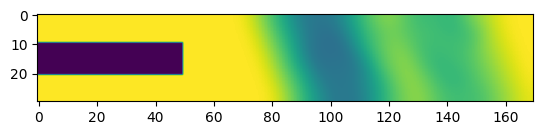

In [188]:
from scipy.ndimage import gaussian_filter
v_image = vp.copy()
v_image[:,50:,:] = gaussian_filter(vp[:,50:,:], sigma=3)
plt.imshow(v_image[15,:,:].T)

In [189]:
source_index=[]

for s in source_list:

    source_index.append(
        (
            int(round(s[0]/dx)),
            int(round(s[1]/dx)),
            int(round(s[2]/dx))
        )
    )


receiver_index=np.zeros(
    (len(receiver_xyz),3),
    dtype=np.int32
)


for i,r in enumerate(receiver_xyz):

    receiver_index[i]=(
        int(round(r[0]/dx)),
        int(round(r[1]/dx)),
        int(round(r[2]/dx))
    )



print("source index:")
print(source_index)


print("receiver index:")
print(receiver_index)



# ======================================================
# 4. 计算走时场
# ======================================================

nsrc=len(source_index)
nrec=len(receiver_index)


# 
# travel_time:
#
# (nsrc,nrec,nx,ny,nz)
#
nx, ny, nz = vp.shape
travel_time=np.empty(
    (
        nsrc,
        nrec,
        nx,
        ny,
        nz
    ),
    dtype=np.float64
)



for isrc,src in enumerate(source_index):

    print(
        f"compute source {isrc+1}/{nsrc}"
    )


    # 当前震源到全空间
    T_source = compute_travel_time_field_numba(
        v_image,
        src,
        receiver_index,
        dx
    )


    #
    # 你的函数返回:
    #
    # (nx,ny,nz,nrec)
    #
    # 转换:
    #
    # (nrec,nx,ny,nz)
    #

    travel_time[isrc,:,:,:,:]=(
        T_source.transpose(3,0,1,2)
    )



print(
    "travel time finished:",
    travel_time.shape
)



# ======================================================
# 5. 整理地震数据
# ======================================================

#
# 原始:
#
# recv.shape=(nt,nrec,nsrc)
#
# (2000,12,2)
#


nt,nrec_data,nsrc_data=recv.shape


assert nrec_data==nrec
assert nsrc_data==nsrc



#
# 转换为:
#
# (nsrc,nrec,nt)
#

seismic_data=recv.transpose(
    2,1,0
).astype(
    np.float32
)



print(
    "seismic data:",
    seismic_data.shape
)



# ======================================================
# 6. 绕射叠加
# ======================================================


# dt=0.001   # 根据你的采样间隔修改


image=diffraction_stack_numba(
    seismic_data,
    travel_time,
    dt
)



print(
    "image shape:",
    image.shape
)



# ======================================================
# 7. 保存
# ======================================================

# np.save(
#     "diffraction_image.npy",
#     image
# )

print("done")

source index:
[(8, 45, 15), (22, 45, 15)]
receiver index:
[[ 8 35 15]
 [ 8 33 15]
 [ 8 31 15]
 [ 8 29 15]
 [ 8 27 15]
 [ 8 25 15]
 [22 35 15]
 [22 33 15]
 [22 31 15]
 [22 29 15]
 [22 27 15]
 [22 25 15]]
compute source 1/2
compute source 2/2
travel time finished: (2, 12, 30, 170, 30)
seismic data: (2, 12, 1500)
image shape: (30, 170, 30)
done


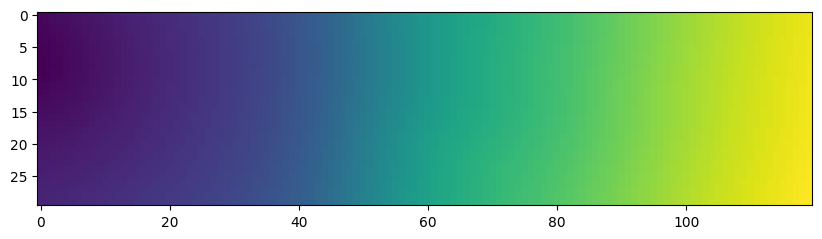

In [190]:
%matplotlib inline
plt.figure(figsize=(10, 3))
plt.imshow(travel_time[0,1,:,50:,15])

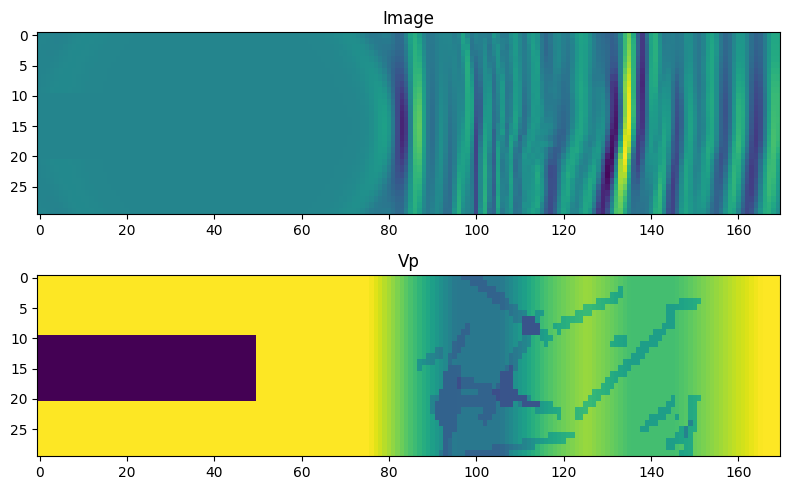

In [200]:
import matplotlib.pyplot as plt
import numpy as np



fig, axes = plt.subplots(2, 1, figsize=(8, 5)) # 2 rows, 1 col

# 上子图
# im1 = axes[0].imshow(image[:,:,15], aspect='auto',vmin = 0.1*image.min(),vmax=0.1*image.max())
im1 = axes[0].imshow(image[:,:,15], aspect='auto',vmin = image.min(),vmax=image.max())
axes[0].set_title('Image')

# 下子图
im2 = axes[1].imshow(vp[:,:,15], aspect='auto')
axes[1].set_title('Vp')

plt.tight_layout()
plt.show()

In [192]:
image.max()

8.259901e-05

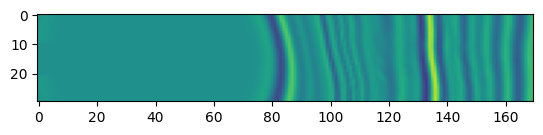

In [193]:
plt.imshow(image[15,:,:].T,vmin=-0.0001,vmax=0.0001)

In [194]:
v_image.max()

5541.000000000001

In [195]:
v_image.min()

0.0010000000474974513

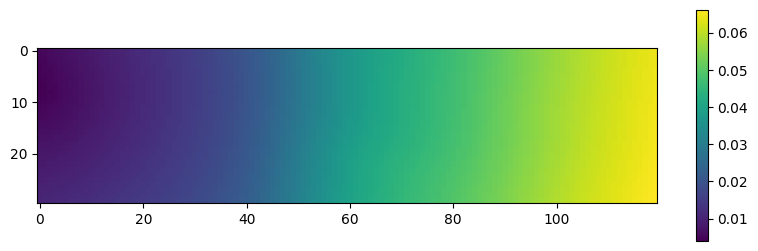

In [196]:
plt.figure(figsize=(10, 3))
plt.imshow(travel_time[0,1,:,50:,15])
plt.colorbar()